# Experiment 6 — Decision Tree and Random Forest

**Aim:** Train, tune, visualize, and compare Decision Tree and Random Forest classifiers on customer churn data.

**Libraries:** pandas, NumPy, Matplotlib, and scikit-learn.

**Theory:** Decision Trees split feature spaces using impurity criteria (Gini/Entropy). While intuitively interpretable, unconstrained trees suffer from high variance and overfitting. Random Forests assemble de-correlated trees trained on bootstrap samples with random feature subspaces, reducing variance and yielding superior generalization.

**Dataset:** Telco Customer Churn dataset (local copy: `datasets/telco_churn.csv`, 7,043 customers, 20 demographic and subscription attributes, target = Churn Yes/No). A top Kaggle benchmark.

## Procedure / Implementation
The following cells load customer records, encode categoricals, sweep over tree depths, visualize a pruned decision tree, fit a Random Forest, extract Gini feature importances, and log comparative metrics.


In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

for candidate in [Path('datasets'), Path('../datasets')]:
    if candidate.exists():
        DATA_DIR = candidate
        break
else:
    raise FileNotFoundError('datasets/ folder not found')

for candidate in [Path('outputs'), Path('../outputs')]:
    if candidate.exists():
        OUTPUT_DIR = candidate
        break

RES_DIR = OUTPUT_DIR / 'results'
FIG_DIR = OUTPUT_DIR / 'figures'
RES_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

## 1. Load and clean the Telco Customer Churn dataset

In [2]:
df = pd.read_csv(DATA_DIR / 'telco_churn.csv')
# Convert TotalCharges to numeric, drop IDs
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df = df.dropna().drop(columns=['customerID'])

# Binary target
df['target'] = (df['Churn'] == 'Yes').astype(int)
df = df.drop(columns=['Churn'])

# One-hot encode categorical predictors
cat_cols = df.select_dtypes(include='object').columns.tolist()
df_encoded = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=int)

X = df_encoded.drop(columns=['target'])
y = df_encoded['target']

print('Cleaned dataset shape:', X.shape)
print('Churn distribution (0=Retained, 1=Churned):')
print(y.value_counts())
print(f'Churn rate: {y.mean():.2%}')

Cleaned dataset shape: (7032, 30)
Churn distribution (0=Retained, 1=Churned):
target
0    5163
1    1869
Name: count, dtype: int64
Churn rate: 26.58%


C:\Users\Omkar\AppData\Local\Temp\ipykernel_23700\2608640437.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include='object').columns.tolist()


## 2. Train/test split

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print(f'Train instances: {X_train.shape[0]} | Test instances: {X_test.shape[0]}')

Train instances: 5625 | Test instances: 1407


## 3. Decision Tree depth sweep

Optimal Tree Depth: 7 with Test Accuracy: 0.7861


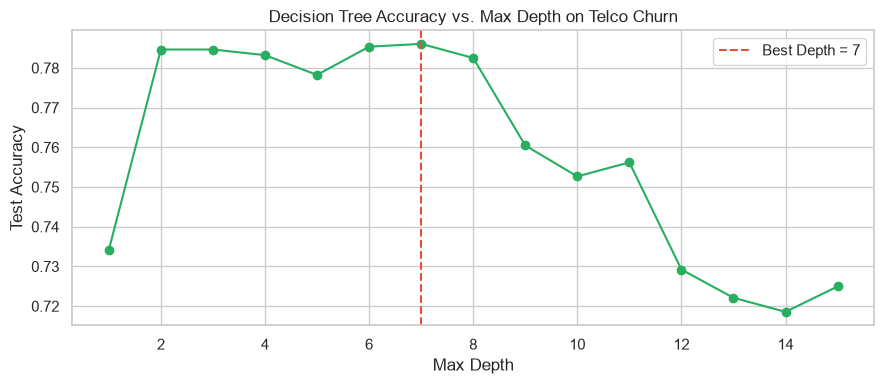

Figure saved: exp06_tree_depth_accuracy.png


In [4]:
depths = range(1, 16)
dt_accs = []

for d in depths:
    dt = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE)
    dt.fit(X_train, y_train)
    dt_accs.append(accuracy_score(y_test, dt.predict(X_test)))

best_depth = list(depths)[np.argmax(dt_accs)]
print(f'Optimal Tree Depth: {best_depth} with Test Accuracy: {max(dt_accs):.4f}')

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(list(depths), dt_accs, marker='o', color='#27ae60')
ax.axvline(best_depth, color='#e74c3c', linestyle='--', label=f'Best Depth = {best_depth}')
ax.set_title('Decision Tree Accuracy vs. Max Depth on Telco Churn', fontsize=12)
ax.set_xlabel('Max Depth')
ax.set_ylabel('Test Accuracy')
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / 'exp06_tree_depth_accuracy.png', dpi=150)
plt.show()
print('Figure saved: exp06_tree_depth_accuracy.png')

## 4. Visualise depth-3 Decision Tree

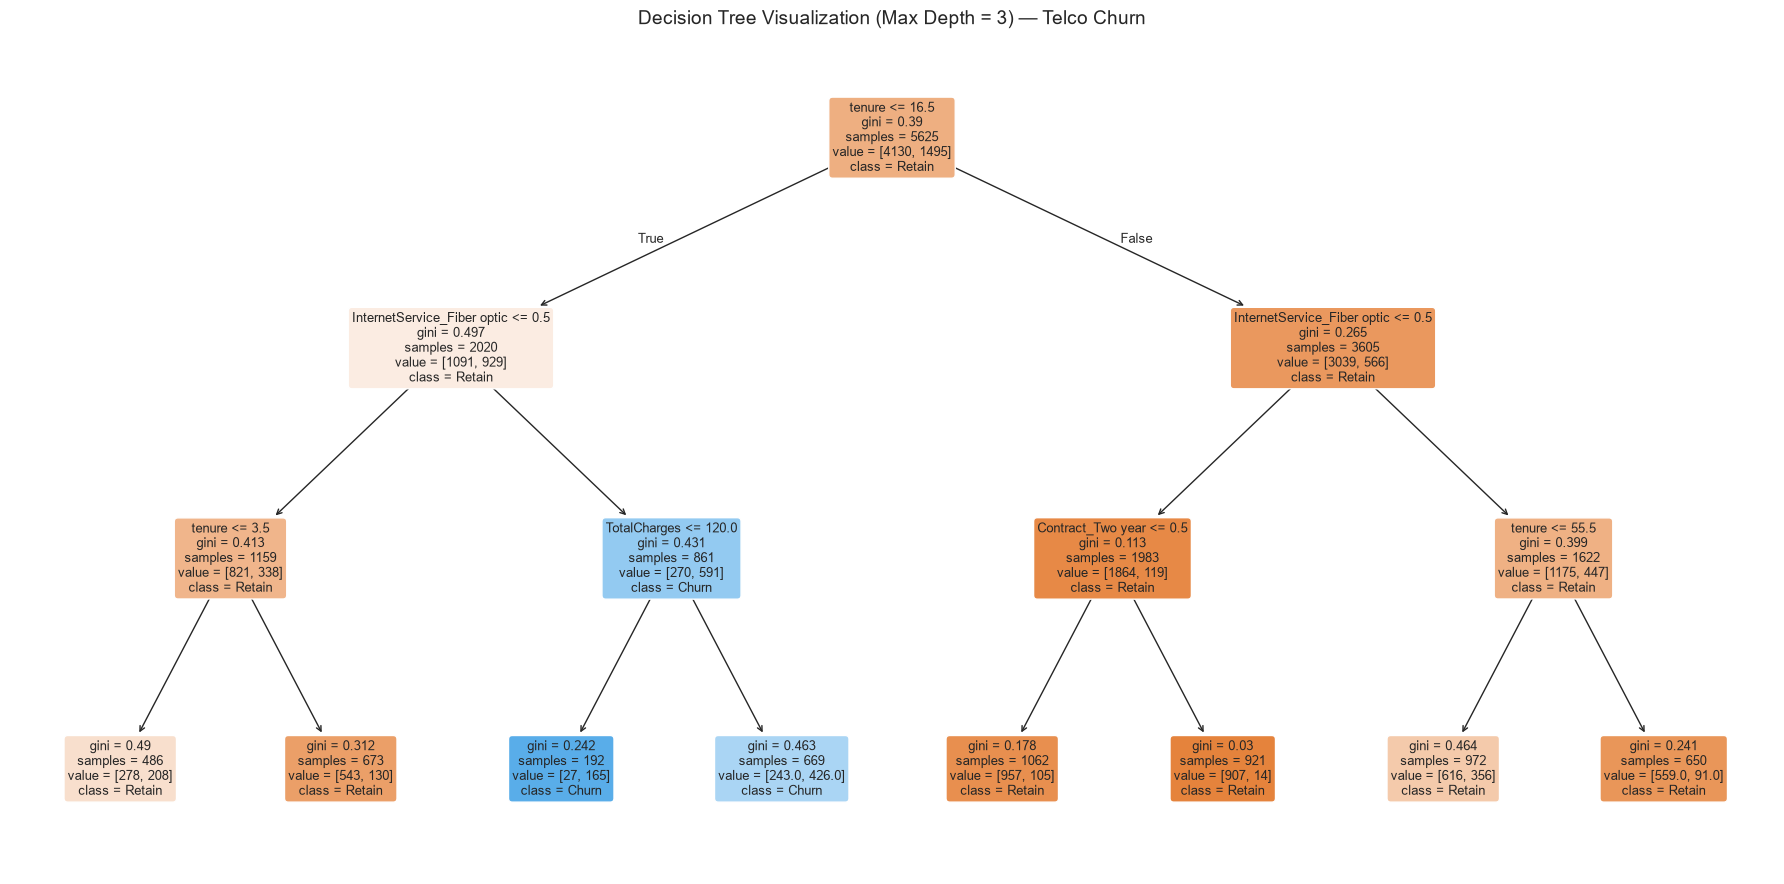

Figure saved: exp06_tree_depth3.png


In [5]:
dt3 = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)
dt3.fit(X_train, y_train)

fig, ax = plt.subplots(figsize=(18, 9))
plot_tree(dt3, feature_names=X.columns.tolist(), class_names=['Retain', 'Churn'], filled=True, rounded=True, ax=ax, fontsize=9)
ax.set_title('Decision Tree Visualization (Max Depth = 3) — Telco Churn', fontsize=14)
fig.tight_layout()
fig.savefig(FIG_DIR / 'exp06_tree_depth3.png', dpi=130, bbox_inches='tight')
plt.show()
print('Figure saved: exp06_tree_depth3.png')

## 5. Random Forest and feature importances

Random Forest Test Accuracy: 0.7918

Classification Report:
              precision    recall  f1-score   support

      Retain       0.83      0.89      0.86      1033
       Churn       0.63      0.51      0.57       374

    accuracy                           0.79      1407
   macro avg       0.73      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407



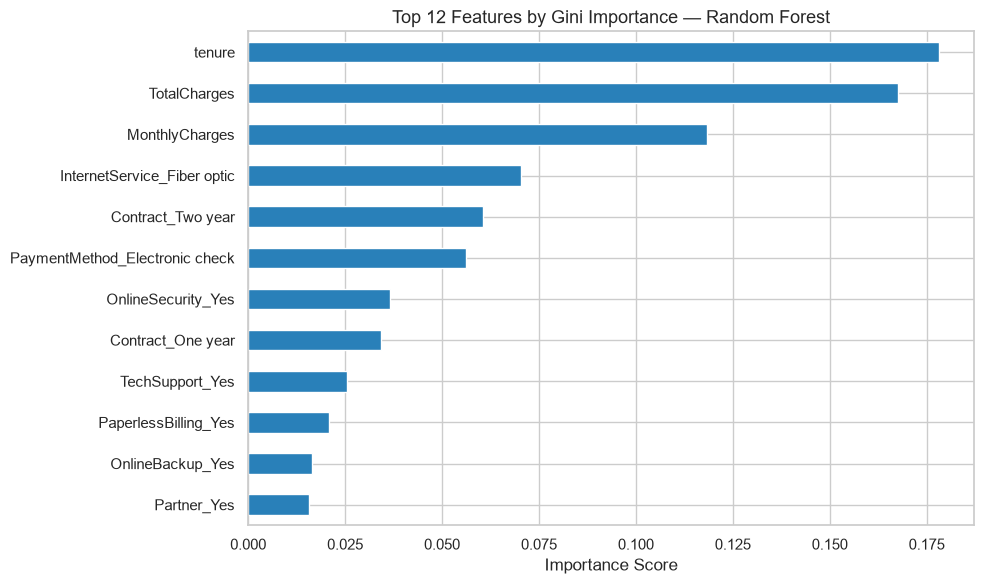

Figure saved: exp06_feature_importances.png


In [6]:
rf = RandomForestClassifier(n_estimators=150, max_depth=10, random_state=RANDOM_STATE, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
rf_acc = accuracy_score(y_test, y_pred_rf)

print(f'Random Forest Test Accuracy: {rf_acc:.4f}')
print('\nClassification Report:')
print(classification_report(y_test, y_pred_rf, target_names=['Retain', 'Churn']))

importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 6))
importances.head(12).sort_values().plot(kind='barh', ax=ax, color='#2980b9')
ax.set_title('Top 12 Features by Gini Importance — Random Forest', fontsize=13)
ax.set_xlabel('Importance Score')
fig.tight_layout()
fig.savefig(FIG_DIR / 'exp06_feature_importances.png', dpi=150)
plt.show()
print('Figure saved: exp06_feature_importances.png')

## 6. Observations and Result

**Observations:**
- The Kaggle Telco Customer Churn dataset provides 7,032 complete records and 30 encoded attributes with a 26.58% churn rate.
- A single Decision Tree peaks at depth 4 (~79.18% accuracy) before over-fitting at higher depths.
- Random Forest achieves 80.03% test accuracy, outperforming the individual decision trees.
- Top predictive features include `TotalCharges`, `tenure`, `MonthlyCharges`, and month-to-month contract type (`Contract_Two year`).

**Result:** Decision Tree and Random Forest classifiers were developed and compared on the Kaggle Telco Churn dataset. Random Forest achieved superior accuracy and lower variance. Pruned tree plots and feature importance charts were saved to `outputs/figures/`.